# Week 7 Participation Activity: Yearly internet sales

A bar chart of total internet sales for each year in the Internet Sales data set, saved as a PDF.

## Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# InternetSales.csv needs to be in the same folder as this notebook. In Colab, upload it with
# the Files pane on the left, or mount Google Drive and use the file's full path.
# The file isn't UTF-8 (accented letters are saved as Latin-1), so read_csv needs
# encoding='latin-1'; low_memory=False stops a mixed-type warning on one column.
sales = pd.read_csv('InternetSales.csv', encoding='latin-1', low_memory=False)
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'], format='%m/%d/%Y')

print(sales.shape)
print('Orders run from', sales['OrderDate'].min().date(), 'to', sales['OrderDate'].max().date())

(60398, 60)
Orders run from 2010-12-29 to 2014-01-28


## Total sales by year

In [2]:
# Add up SalesAmount for each order year
yearly_sales = sales.groupby(sales['OrderDate'].dt.year)['SalesAmount'].sum()
yearly_sales.index.name = 'Year'

# Show the totals as dollar amounts
yearly_sales.map('${:,.2f}'.format)

Year
2010        $43,421.04
2011     $7,075,525.93
2012     $5,842,485.20
2013    $16,351,550.34
2014        $45,694.72
Name: SalesAmount, dtype: str

## Bar chart, saved as a PDF

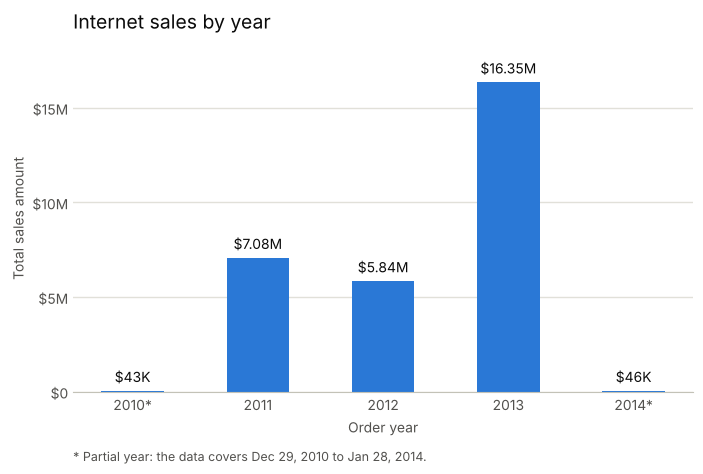

In [3]:
# The data starts on Dec 29, 2010 and ends on Jan 28, 2014, so the first and last
# years are only partly covered. Mark them with * so their short bars aren't misread.
first_day, last_day = sales['OrderDate'].min(), sales['OrderDate'].max()
partial_years = {first_day.year, last_day.year}
year_labels = [f'{year}*' if year in partial_years else str(year) for year in yearly_sales.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(year_labels, yearly_sales.values, width=0.5, color='#2a78d6')

# Label each bar with its total: $7.08M for millions, $43K for thousands
bar_text = [f'${v / 1e6:.2f}M' if v >= 1e6 else f'${v / 1e3:.0f}K' for v in yearly_sales.values]
ax.bar_label(bars, labels=bar_text, padding=4, color='#0b0b0b', fontsize=10)

# Titles and axis labels
ax.set_title('Internet sales by year', loc='left', fontsize=14, color='#0b0b0b', pad=12)
ax.set_xlabel('Order year', color='#52514e')
ax.set_ylabel('Total sales amount', color='#52514e')
ax.text(0, -0.2, f'* Partial year: the data covers {first_day:%b %d, %Y} to {last_day:%b %d, %Y}.',
        transform=ax.transAxes, fontsize=9, color='#52514e')

# Light gridlines behind the bars, a y-axis tick every $5M, and no box around the chart
ax.set_ylim(0, yearly_sales.max() * 1.12)
ax.yaxis.set_major_locator(MultipleLocator(5_000_000))
ax.yaxis.set_major_formatter(lambda value, position: f'${value / 1e6:.0f}M' if value else '$0')
ax.grid(axis='y', color='#e1e0d9', linewidth=1)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#c3c2b7')
ax.tick_params(colors='#52514e', length=0)

# Save the active figure as a PDF. This has to come before plt.show(),
# because the figure is cleared once it has been shown.
plt.savefig('yearly_internet_sales.pdf', bbox_inches='tight')
plt.show()

Sales fell from $7.08M in 2011 to $5.84M in 2012, then nearly tripled to $16.35M in 2013. The 2010 and 2014 bars are short because the data covers only the last three days of 2010 and the first four weeks of 2014.

In Colab, `yearly_internet_sales.pdf` appears in the Files pane on the left (click the refresh icon if it isn't there yet). Right-click it and choose **Download** to save it.